# Project: Sardine Run — Ichthyop particle simulation
# Data: CMEMS GLORYS12V1
# Input: sardinetrial.nc
# N =-29.5, W=25.5, E=31.5, S=-34.5
# time series 01/05/2023 to 01/08/2023
# depth min 0.49 to depth max 5727.92 m

In [2]:
from pathlib import Path
import numpy as np
import xarray as xr



In [3]:
project_dir = Path.home() / "Research" / "Ichthyop-Workshop"

nc_file = (
    project_dir
    / "software"
    / "input"
    / "sardinetrial.nc"
)


In [5]:
data = xr.open_dataset(nc_file)
data

<xarray.Dataset> Size: 247MB
Dimensions:    (time: 93, latitude: 61, longitude: 72, depth: 50)
Coordinates:
  * time       (time) datetime64[ns] 744B 2023-05-01 2023-05-02 ... 2023-08-01
  * latitude   (latitude) float32 244B -34.5 -34.42 -34.33 ... -29.58 -29.5
  * longitude  (longitude) float32 288B 25.5 25.58 25.67 ... 31.25 31.33 31.42
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
Data variables:
    bottomT    (time, latitude, longitude) float32 2MB ...
    thetao     (time, depth, latitude, longitude) float32 82MB ...
    uo         (time, depth, latitude, longitude) float32 82MB ...
    vo         (time, depth, latitude, longitude) float32 82MB ...
Attributes:
    Conventions:       CF-1.11
    title:             daily mean fields from Global Ocean Physics Analysis a...
    institution:       MERCATOR OCEAN
    source:            MERCATOR GLORYS12V1
    history:           2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    references:        http://www.mercator-ocean.fr
    comment:           CMEMS product
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_PHY_001_030
    subset:datasetId:  cmems_mod_glo_phy_my_0.083deg_P1D-m_202311
    subset:date:       2026-10-20T09:03:36.108Z

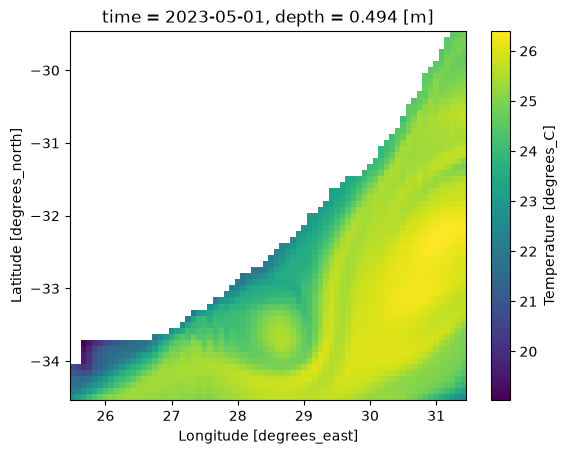

In [6]:
data['thetao'].isel(time=0, depth=0).plot()

In [7]:
abs(data["uo"]).max().values, abs(data["vo"]).max().values


(array(1.9800409, dtype=float32), array(2.362743, dtype=float32))

In [8]:
project_dir = Path.home() / "Research" / "Ichthyop-Workshop"

nc_file = (
    project_dir
    / "software"
    / "input"
    / "sardinecoords.nc"
)

# Finding coords

# E1t x
# E2t y
# E3t z

In [9]:
data = xr.open_dataset(nc_file)
data 

<xarray.Dataset> Size: 36kB
Dimensions:    (latitude: 61, longitude: 72, depth: 50)
Coordinates:
  * latitude   (latitude) float32 244B -34.5 -34.42 -34.33 ... -29.58 -29.5
  * longitude  (longitude) float32 288B 25.5 25.58 25.67 ... 31.25 31.33 31.42
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
Data variables:
    e1t        (latitude, longitude) float32 18kB ...
    e2t        (latitude, longitude) float32 18kB ...
    e3t        (depth) float32 200B ...
Attributes:
    Conventions:       CF-1.11
    title:             Static fields for product GLOBAL_REANALYSIS_PHY_001_030
    institution:       Mercator Ocean
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MERCATOR GLORYS12V1
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_PHY_001_030
    subset:datasetId:  cmems_mod_glo_phy_my_0.083deg_static_202311--ext--coords
    subset:date:       2026-10-20T09:15:56.578Z

In [10]:
data["e1t"].min(), data["e2t"].min()

(<xarray.DataArray 'e1t' ()> Size: 4B
 array(7645.0645, dtype=float32)
 Attributes:
     units:      m
     long_name:  Cell dimension along X axis,
 <xarray.DataArray 'e2t' ()> Size: 4B
 array(9276.57, dtype=float32)
 Attributes:
     units:      m
     long_name:  Cell dimension along Y axis)

In [11]:
data = xr.open_dataset('/Users/savannahanderson/Research/Ichthyop-Workshop/software/output/my-simulation_ichthyop-run202610211140.nc')
data

<xarray.Dataset> Size: 638kB
Dimensions:       (time: 31, drifter: 1000, edge: 262, latlon: 2)
Coordinates:
  * time          (time) datetime64[ns] 248B 2023-05-01 ... 2023-05-31
  * drifter       (drifter) int32 4kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
Dimensions without coordinates: edge, latlon
Data variables:
    age           (time, drifter) float32 124kB ...
    lon           (time, drifter) float32 124kB ...
    lat           (time, drifter) float32 124kB ...
    mortality     (time, drifter) int32 124kB ...
    depth         (time, drifter) float32 124kB ...
    lat_init      (drifter) float32 4kB ...
    lon_init      (drifter) float32 4kB ...
    release_zone  (drifter) int32 4kB ...
    region_edge   (edge, latlon) float32 2kB ...
Attributes: (12/84)
    transport_dimension:                   3d
    release.schedule.is_enabled:           false
    release.schedule.events:               
    app.time.initial_time:                 year 2023 month 05 day 01 at 00:00
    app.time.transport_duration:           0030 day(s) 00 hour(s) 00 minute(s)
    app.time.keep_drifting:                true
    ...                                    ...
    dataset.mercator3d.field_var_time:     time
    dataset.mercator3d.field_var_e3t:      e3t
    dataset.mercator3d.field_var_e2t:      e2t
    dataset.mercator3d.field_var_e1t:      e1t
    xml_file:                              /Users/savannahanderson/Research/I...
    nb_zones:                              0

In [ ]:
data = xr.open_dataset(nc_file)
data 

<xarray.Dataset> Size: 36kB
Dimensions:    (latitude: 61, longitude: 72, depth: 50)
Coordinates:
  * latitude   (latitude) float32 244B -34.5 -34.42 -34.33 ... -29.58 -29.5
  * longitude  (longitude) float32 288B 25.5 25.58 25.67 ... 31.25 31.33 31.42
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
Data variables:
    e1t        (latitude, longitude) float32 18kB ...
    e2t        (latitude, longitude) float32 18kB ...
    e3t        (depth) float32 200B ...
Attributes:
    Conventions:       CF-1.11
    title:             Static fields for product GLOBAL_REANALYSIS_PHY_001_030
    institution:       Mercator Ocean
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MERCATOR GLORYS12V1
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_PHY_001_030
    subset:datasetId:  cmems_mod_glo_phy_my_0.083deg_static_202311--ext--coords
    subset:date:       2026-10-20T09:15:56.578Z

In [12]:
temp = data.isel(time=-1)
import matplotlib.pyplot as plt

In [13]:
temp['mortality']

<xarray.DataArray 'mortality' (drifter: 1000)> Size: 4kB
[1000 values with dtype=int32]
Coordinates:
  * drifter  (drifter) int32 4kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
    time     datetime64[ns] 8B 2023-05-31
Attributes:
    long_name:      particle cause of mortality
    unit:           death cause
    alive:          0
    dead_cold:      1
    out_of_domain:  2
    old:            3
    beached:        4
    starvation:     5
    dead_hot:       6
    dead_fresh:     7
    dead_saline:    8
    large:          9

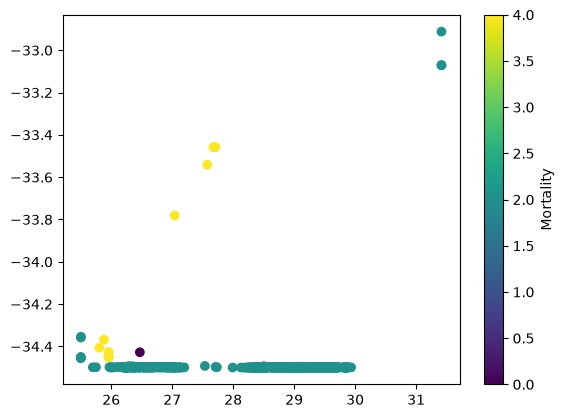

In [14]:
cs = plt.scatter(temp['lon'], temp['lat'], c=temp['mortality'], cmap='viridis')
plt.colorbar(cs, label='Mortality')


--- SURFACE DATA COVERAGE ---
Missing surface data: 55.15%
Valid surface data: 44.85%

--- OCEAN MASK ---
Valid ocean cells: 1970
Total grid cells: 4392


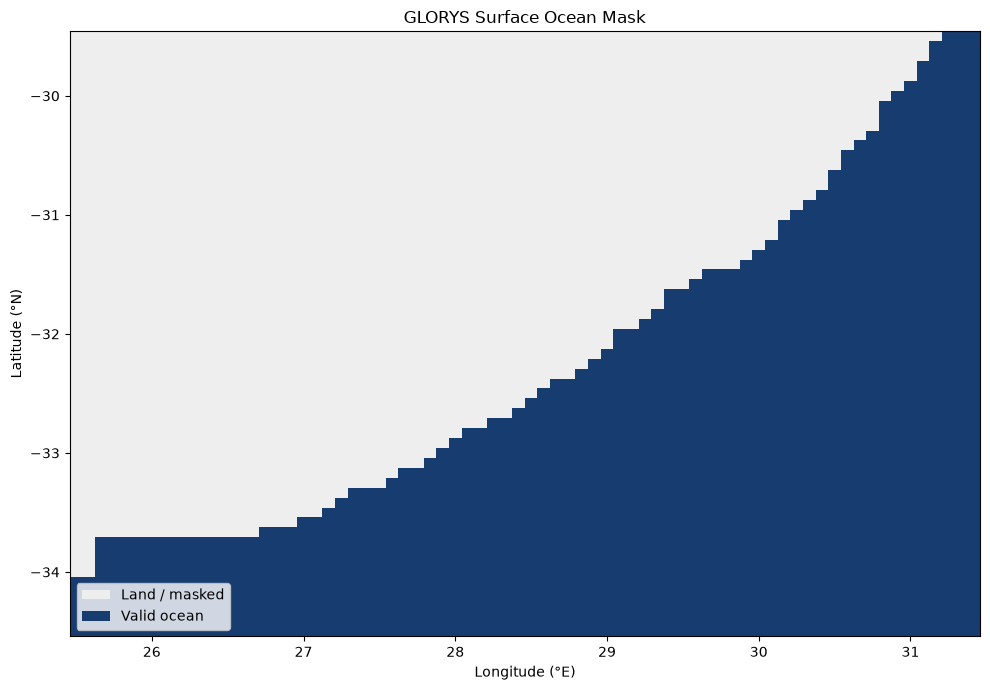

In [17]:
project_dir = Path.home() / "Research" / "Ichthyop-Workshop"

nc_file = (
    project_dir / "software" / "input" / "sardinetrial.nc"
)

ds = xr.open_dataset(nc_file)

# Select shallowest depth level
u_surface = ds["uo"].isel(depth=0)

# Calculate valid and missing fractions across time
surface_missing = u_surface.isnull().mean().item() * 100

print("\n--- SURFACE DATA COVERAGE ---")
print(f"Missing surface data: {surface_missing:.2f}%")
print(f"Valid surface data: {100 - surface_missing:.2f}%")

ocean_mask = u_surface.notnull().any(dim="time")

print("\n--- OCEAN MASK ---")
print(f"Valid ocean cells: {int(ocean_mask.sum().item())}")
print(f"Total grid cells: {ocean_mask.size}")

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 7))

cmap = ListedColormap(["#eeeeee", "#173c70"])

ocean_mask.astype(int).plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=1,
    add_colorbar=False
)

ax.legend(
    handles=[
        Patch(facecolor="#eeeeee", label="Land / masked"),
        Patch(facecolor="#173c70", label="Valid ocean")
    ],
    loc="lower left"
)

ax.set_title("GLORYS Surface Ocean Mask")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

plt.tight_layout()

output_dir = project_dir / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "glorys_ocean_mask.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
ds.close()

print("\nOcean mask analysis complete.")


Ocean mask analysis complete.


In [ ]:
# %% FILE PATHS
# %% for release site selection
project_dir = Path.home() / "Research" / "Ichthyop-Workshop"

nc_file = (
    project_dir
    / "software"
    / "input"
    / "sardinetrial.nc"
)

output_dir = project_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)

ds = xr.open_dataset(nc_file)

# %% 3. DEFINE RELEASE SITES 

release_sites = {
    "Test_site_01": {
        "latitude": -33.666668,
        "longitude": 28.833345
    }
}

# Simulation period: inclusive daily records
start_date = "2023-05-01"
end_date = "2023-08-01"

simulation = ds.sel(
    time=slice(start_date, end_date)
)

if simulation.sizes["time"] == 0:
    raise ValueError("No forcing records in selected period.")
